# Sección 4 · Modelos de pronóstico y validación temporal

Ahora sí pronosticamos. La pregunta de esta sección no es "¿qué tan bajo es el error?", sino:

> **¿Un modelo de machine learning pronostica mejor que las reglas simples que usaría cualquier operador?**

Si no les gana a las referencias simples, el modelo no aporta nada. Por eso **todos los modelos se evalúan con los mismos datos, los mismos meses y las mismas métricas**.

| Tipo | Modelo | Idea |
|---|---|---|
| Referencia | **Ingenuo** | El próximo mes = el último mes observado |
| Referencia | **Ingenuo estacional** | El próximo mes = el mismo mes del año anterior |
| Referencia | **Promedio 3 meses** | El próximo mes = el promedio de los últimos 3 |
| Clásico local | **ETS (Holt amortiguado)** | Un modelo de series de tiempo **por localidad** (nivel + tendencia amortiguada) |
| ML global | **Random Forest** | **Un solo modelo** para todas las localidades (el que ya usabas, ahora bien planteado) |
| ML global | **Gradient Boosting** | Un solo modelo, de la familia de LightGBM/XGBoost |

Horizontes: **1 mes** (principal) y **3 meses**.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings, time
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from statsmodels.tsa.holtwinters import ExponentialSmoothing

warnings.filterwarnings("ignore", module="statsmodels")
FIG = Path("../figuras")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160)

p = pd.read_csv("../datos/processed/energia_eda.csv", parse_dates=["fecha"]).sort_values(["id_loc", "fecha"])
print(p.id_loc.nunique(), "localidades elegibles |", len(p), "filas")

78 localidades elegibles | 3071 filas


## 4.1 Qué predecimos exactamente

Siguiendo la Sección 3, el objetivo es el **logaritmo de la energía por día**:

$$y_t = \ln\left(\frac{E_t}{\text{días}_t}\right)$$

**¿Por qué el logaritmo?**
- Los errores pasan a ser **relativos**: equivocarse en 0,05 es ~5 % en San Andrés y ~5 % en una vereda. Así el modelo no se dedica solo a San Andrés.
- Un pronóstico en log, al volver con `exp()`, **nunca da energía negativa**.
- Las variaciones de energía son multiplicativas ("creció 3 %"), y en log se vuelven sumas.

**¿Qué pasa con los meses sin servicio (energía ≈ 0)?** El log de 0 no existe. Además, un apagón **no se puede pronosticar** con estos datos (depende de fallas o de combustible). Se excluyen como objetivo y esto se reporta como **limitación**: el modelo pronostica la energía **en los meses en que el sistema opera**.

Al final, todo pronóstico vuelve a **kWh/mes** (× días del mes) para medir el error en las unidades reales.

In [2]:
p["y"] = np.log((p.e_activa / p.dias).where(p.e_activa > 5))   # NaN si no hubo servicio o falta el mes
print("Meses con objetivo válido:", p.y.notna().sum(), "| sin servicio (excluidos):", (p.sin_servicio).sum(),
      "| faltantes:", p.mes_faltante.sum())

Meses con objetivo válido: 2782 | sin servicio (excluidos): 6 | faltantes: 281


## 4.2 Variables (todas conocidas en el momento de pronosticar)

Llamamos **origen** al último mes con datos al momento de pronosticar, y **objetivo** al mes que queremos predecir (origen + *h*).

**Regla de oro anti-fuga:** cada variable se calcula **solo con información del origen o antes**.

Siguiendo la Sección 3 (los árboles no extrapolan y hay tendencia), el modelo de ML **no predice el nivel**, sino **cuánto se aleja el objetivo del nivel reciente**:

$$\text{nivel reciente} = \text{promedio}(y_{origen},\ y_{origen-1},\ y_{origen-2})$$
$$\text{lo que aprende el modelo} = y_{objetivo} - \text{nivel reciente}$$

Así, si una localidad crece y alcanza valores nunca vistos, el modelo no queda "atascado": solo tiene que estimar el **cambio**, que sí es parecido entre localidades. Por eso un modelo **global** puede aprender de todas a la vez.

| Variable | Qué es | Por qué (Sección 3) |
|---|---|---|
| `nivel` | Promedio de log kWh/día de los últimos 3 meses | Tamaño de la localidad |
| `lag0`, `lag1`, `lag2` | Cada uno de los 3 últimos meses **menos** el nivel | Persistencia y choques recientes (¿el último mes fue anómalo?) |
| `lag_est` | El mismo mes del año anterior menos el nivel | Estacionalidad (débil, pero se prueba) |
| `horas0`, `horas1` | Horas de servicio en el origen y en el mes anterior | Energía limitada por la oferta |
| `dhoras0` | Cambio de horas en el último mes | Choque de servicio reciente → posible recuperación |
| `horas_med` | Mediana histórica de horas (hasta el origen) | Tipo de sistema: 24 h o limitado |
| `parcial0` | ¿El último mes fue de servicio parcial? | Choque que tiende a revertirse |
| `n_obs3` | Cuántos de los últimos 3 meses existen | Calidad de la información reciente |
| `mes_obj` | Mes del año del objetivo | Diciembre y enero |
| `covid_obj` | ¿El objetivo cae en el periodo COVID? | Choque de 2020 |

Los meses faltantes quedan como `NaN`. **Random Forest y Gradient Boosting de scikit-learn ≥ 1.4 manejan `NaN` directamente**, así que no hay que inventar valores. Esta es la decisión que dejamos pendiente en la Sección 2.

In [3]:
VARIABLES = ["nivel", "lag0", "lag1", "lag2", "lag_est", "horas0", "horas1", "dhoras0",
             "horas_med", "parcial0", "n_obs3", "mes_obj", "covid_obj"]

def construir_tabla(p, h):
    # Una fila por (localidad, origen). Variables en el origen; objetivo en origen + h
    g = p.groupby("id_loc")
    l0, l1, l2 = p.y, g.y.shift(1), g.y.shift(2)
    ultimos3 = pd.concat([l0, l1, l2], axis=1)
    nivel = ultimos3.mean(axis=1)                        # promedio ignorando faltantes
    objetivo = p.fecha + pd.DateOffset(months=h)
    T = pd.DataFrame({
        "id_loc": p.id_loc, "nombre": p.nombre_corto, "tamano": p.tamano, "origen": p.fecha, "objetivo": objetivo,
        "dias_obj": objetivo.dt.days_in_month,
        "y_obj": g.y.shift(-h),                           # lo que queremos predecir
        "nivel": nivel,
        "lag0": l0 - nivel, "lag1": l1 - nivel, "lag2": l2 - nivel,
        "lag_est": g.y.shift(12 - h) - nivel,
        "horas0": p.horas_dia, "horas1": g.horas_dia.shift(1),
        "dhoras0": p.horas_dia - g.horas_dia.shift(1),
        "horas_med": g.horas_dia.transform(lambda s: s.expanding().median()),
        "parcial0": p.servicio_parcial.astype(int),
        "n_obs3": ultimos3.notna().sum(axis=1),
        "mes_obj": objetivo.dt.month,
        "covid_obj": objetivo.between("2020-03-01", "2020-12-01").astype(int),
        # pronósticos de las referencias (en log kWh/día)
        "pred_ingenuo": g.y.ffill(),                       # último valor observado
        "pred_estacional": g.y.shift(12 - h),
        "pred_promedio3": nivel,
    })
    T["pred_estacional"] = T.pred_estacional.fillna(T.pred_ingenuo)   # sin dato de hace 12 meses → ingenuo
    return T[T.nivel.notna()]

tabla_h1 = construir_tabla(p, 1)
tabla_h1[["nombre", "origen", "objetivo", "y_obj", "nivel", "lag0", "horas0", "pred_ingenuo"]].head(6).round({"y_obj": 3, "nivel": 3, "lag0": 3, "pred_ingenuo": 3})

,nombre,origen,objetivo,y_obj,nivel,lag0,horas0,pred_ingenuo
0,Vegáez,2020-01-01,2020-02-01,5.185,4.270,0.000,3.17,4.270
1,Vegáez,2020-02-01,2020-03-01,4.990,4.727,0.457,5.40,5.185
2,Vegáez,2020-03-01,2020-04-01,5.035,4.815,0.175,5.70,4.990
3,Vegáez,2020-04-01,2020-05-01,5.313,5.070,-0.035,4.58,5.035
4,Vegáez,2020-05-01,2020-06-01,5.285,5.113,0.200,6.27,5.313
5,Vegáez,2020-06-01,2020-07-01,5.207,5.211,0.074,6.35,5.285


## 4.3 Validación con origen rodante (el reemplazo de `train_test_split`)

Simulamos cómo se usaría el modelo en la vida real. Para cada mes de prueba entre **julio de 2022 y junio de 2023** (12 meses):

1. Nos paramos en el **origen** (por ejemplo, junio de 2022 para pronosticar julio a 1 mes).
2. Entrenamos **solo con filas cuyo objetivo es ≤ origen**, es decir, con datos que en ese momento ya existían.
3. Pronosticamos el mes objetivo y guardamos el error.
4. Avanzamos un mes y **reentrenamos** con la nueva información.

Así cada pronóstico se evalúa con datos que el modelo **nunca vio**, y el periodo de prueba (2022–2023) queda fuera del COVID.

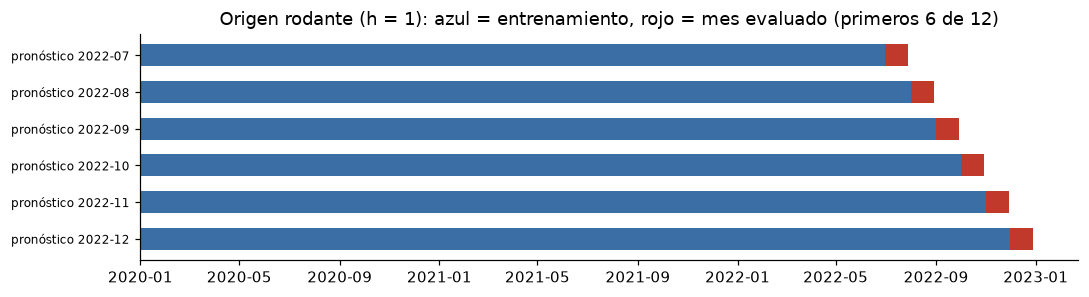

In [4]:
PRUEBA = pd.date_range("2022-07-01", "2023-06-01", freq="MS")

fig, ax = plt.subplots(figsize=(10, 2.8))
for i, T in enumerate(PRUEBA[:6]):
    origen = T - pd.DateOffset(months=1)
    ax.barh(i, (T - pd.Timestamp("2020-01-01")).days, left=pd.Timestamp("2020-01-01"), color="#3b6ea5", height=0.6)  # hasta el fin del origen
    ax.barh(i, 28, left=T, color="#c0392b", height=0.6)
ax.set_yticks(range(6)); ax.set_yticklabels([f"pronóstico {T:%Y-%m}" for T in PRUEBA[:6]], fontsize=8)
ax.invert_yaxis(); ax.set_title("Origen rodante (h = 1): azul = entrenamiento, rojo = mes evaluado (primeros 6 de 12)")
fig.tight_layout(); fig.savefig(FIG / "s4_origen_rodante.png"); plt.show()

## 4.4 Los modelos

- **ETS local (Holt con tendencia amortiguada):** un modelo clásico de series de tiempo para **cada localidad** por separado. Estima un nivel y una tendencia que se "frena" con el horizonte. Es el tipo de modelo de los papers de pronóstico mensual del SIN (Revista EIA). Necesita series sin huecos, así que para ajustarlo se interpolan los huecos internos (solo para este modelo).
- **Random Forest global:** promedio de cientos de árboles de decisión entrenados con todas las localidades. `min_samples_leaf=5` evita que memorice casos individuales.
- **Gradient Boosting global:** árboles en secuencia, donde cada uno corrige los errores del anterior. Es la misma idea de LightGBM.

Los hiperparámetros se fijan con valores razonables y **no se ajustan mirando el periodo de prueba**. Ajustarlos así sería otra forma de fuga.

In [5]:
def pronostico_ets(p, id_loc, origen, h):
    s = p[(p.id_loc == id_loc) & (p.fecha <= origen)].set_index("fecha").y
    s = s.interpolate(limit_area="inside").dropna()
    try:
        return ExponentialSmoothing(s.values, trend="add", damped_trend=True).fit().forecast(h)[-1]
    except Exception:
        return np.nan

def evaluar(p, h):
    tabla = construir_tabla(p, h)
    resultados, modelos = [], {}
    for T in PRUEBA:
        origen = T - pd.DateOffset(months=h)
        entreno = tabla[(tabla.objetivo <= origen) & tabla.y_obj.notna()]
        prueba = tabla[(tabla.objetivo == T) & tabla.y_obj.notna()].copy()
        X, y = entreno[VARIABLES], entreno.y_obj - entreno.nivel          # se aprende el CAMBIO

        rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.5, random_state=0, n_jobs=-1).fit(X, y)
        gb = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=20,
                                           l2_regularization=1.0, random_state=0).fit(X, y)
        prueba["pred_rf"] = prueba.nivel + rf.predict(prueba[VARIABLES])
        prueba["pred_gb"] = prueba.nivel + gb.predict(prueba[VARIABLES])
        prueba["pred_ets"] = [pronostico_ets(p, l, origen, h) for l in prueba.id_loc]
        prueba["pred_ets"] = prueba.pred_ets.fillna(prueba.pred_promedio3)
        prueba["n_entreno"] = len(entreno)
        resultados.append(prueba)
        modelos[T] = (rf, entreno)
    return pd.concat(resultados), modelos

t0 = time.time()
res_h1, modelos_h1 = evaluar(p, 1)
res_h3, modelos_h3 = evaluar(p, 3)
print(f"Listo en {time.time() - t0:.0f} s | pronósticos evaluados: h=1 → {len(res_h1)}, h=3 → {len(res_h3)}")
print("Filas de entrenamiento: del primer al último origen (h=1):", res_h1.n_entreno.min(), "→", res_h1.n_entreno.max())

Listo en 39 s | pronósticos evaluados: h=1 → 751, h=3 → 743
Filas de entrenamiento: del primer al último origen (h=1): 1920 → 2615


## 4.5 Métricas

Todas se calculan en **kWh/mes reales** (después de deshacer el log y multiplicar por los días):

| Métrica | Fórmula | Qué dice | Cuidado |
|---|---|---|---|
| **sMAPE** | $\frac{2\lvert \hat{E}-E\rvert}{\lvert\hat{E}\rvert+\lvert E\rvert}$ | Error **en %**, comparable entre localidades | Es la métrica principal |
| **MAE** | $\lvert\hat{E}-E\rvert$ promedio | Error en **MWh** | Lo domina San Andrés (51 % de la energía) |
| **MASE** | MAE / error del ingenuo en el entrenamiento | < 1 = mejor que "igual que el mes pasado" (histórico) | Estándar en la literatura de pronóstico |

Reportamos el **promedio** (penaliza los errores grandes) y la **mediana** (el caso típico).

In [6]:
MODELOS = {"pred_ingenuo": "Ingenuo", "pred_estacional": "Ingenuo estacional", "pred_promedio3": "Promedio 3 meses",
           "pred_ets": "ETS local", "pred_rf": "Random Forest global", "pred_gb": "Gradient Boosting global"}

# Escala para MASE: error medio del ingenuo de 1 paso en kWh/mes, por localidad, ANTES del periodo de prueba
hist = p[p.fecha < PRUEBA[0]].copy()
hist["e"] = np.exp(hist.y) * hist.dias
escala = hist.groupby("id_loc").e.apply(lambda s: s.diff().abs().mean())

def metricas(res):
    real = np.exp(res.y_obj) * res.dias_obj
    filas = {}
    for col, nombre in MODELOS.items():
        pred = np.exp(res[col]) * res.dias_obj
        err = (pred - real).abs()
        smape = 2 * err / (pred.abs() + real.abs())
        filas[nombre] = {"sMAPE promedio %": 100 * smape.mean(), "sMAPE mediana %": 100 * smape.median(),
                         "MAE (MWh/mes)": err.mean() / 1000, "MASE": (err / res.id_loc.map(escala)).mean()}
        res["smape_" + col] = smape
    return pd.DataFrame(filas).T

tabla_res = pd.concat({"1 mes": metricas(res_h1), "3 meses": metricas(res_h3)}, axis=1)
tabla_res.round(2)

1 mes                                              3 meses                                    
                         sMAPE promedio % sMAPE mediana % MAE (MWh/mes)  MASE sMAPE promedio % sMAPE mediana % MAE (MWh/mes)  MASE
Ingenuo                             11.99            5.35         20.87  0.97            15.45            7.73         32.15  1.30
Ingenuo estacional                  17.56            9.22         25.39  1.54            17.82            9.40         26.08  1.58
Promedio 3 meses                    12.08            5.87         23.15  1.01            15.25            7.60         29.61  1.29
ETS local                           12.32            6.10         20.26  1.00            15.93            8.70         34.23  1.36
Random Forest global                11.04            5.77         23.53  0.95            13.55            7.43         27.20  1.17
Gradient Boosting global            12.00            5.92         24.76  1.02            14.63            8.47         32.03  1.28

In [7]:
def por_tamano(res):
    return pd.DataFrame({MODELOS[c]: res.groupby("tamano")["smape_" + c].mean() * 100 for c in MODELOS}).T[["pequeña", "mediana", "grande"]]

pd.concat({"1 mes": por_tamano(res_h1), "3 meses": por_tamano(res_h3)}, axis=1).round(1)

1 mes                3 meses               
tamano                   pequeña mediana grande pequeña mediana grande
Ingenuo                     14.8    17.0    5.0    20.1    20.6    6.9
Ingenuo estacional          22.3    23.2    8.3    23.3    22.8    8.6
Promedio 3 meses            15.0    17.0    5.2    19.5    20.8    6.7
ETS local                   16.1    16.9    4.9    21.5    20.8    6.8
Random Forest global        13.2    15.5    5.2    17.7    18.1    6.0
Gradient Boosting global    15.3    16.4    5.2    19.4    18.7    6.9

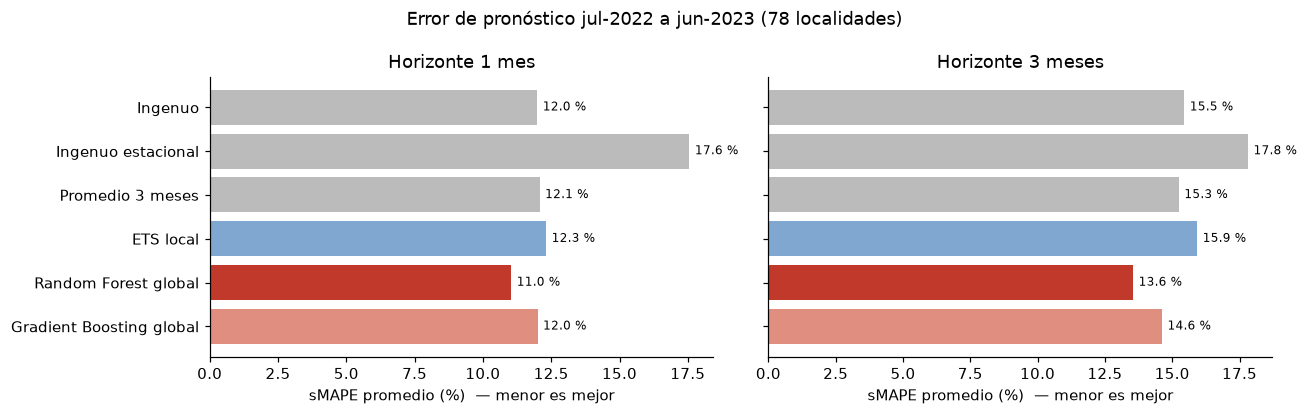

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
colores = ["#bbbbbb", "#bbbbbb", "#bbbbbb", "#7fa7cf", "#c0392b", "#e08e7f"]
for ax, (h, res) in zip(axes, [("1 mes", res_h1), ("3 meses", res_h3)]):
    v = [100 * res["smape_" + c].mean() for c in MODELOS]
    ax.barh(list(MODELOS.values()), v, color=colores)
    for i, x in enumerate(v): ax.text(x + 0.2, i, f"{x:.1f} %", va="center", fontsize=8)
    ax.set(title=f"Horizonte {h}", xlabel="sMAPE promedio (%)  — menor es mejor")
axes[0].invert_yaxis()
fig.suptitle("Error de pronóstico jul-2022 a jun-2023 (78 localidades)")
fig.tight_layout(); fig.savefig(FIG / "s4_comparacion_modelos.png"); plt.show()

## 4.6 ¿La mejora es real o es suerte?

Una diferencia de 1 punto de sMAPE podría deberse al azar: a qué localidades y meses tocó evaluar. Lo comprobamos de dos formas:

1. **¿En cuántas localidades gana el Random Forest al ingenuo?** Si gana en la mayoría, la mejora es general y no viene de unos pocos casos.
2. **Bootstrap por localidad:** remuestreamos las localidades con reemplazo 2.000 veces y recalculamos la diferencia de sMAPE cada vez. Si el intervalo del 95 % **no incluye el 0**, la mejora es estadísticamente sólida.

Se remuestrea **por localidad** y no por fila porque los errores de una misma localidad están correlacionados entre sí.

In [9]:
def comparar(res, a="pred_rf", b="pred_ingenuo", n=2000, semilla=0):
    por_loc = res.groupby("id_loc")[["smape_" + a, "smape_" + b]].mean() * 100
    dif = por_loc["smape_" + a] - por_loc["smape_" + b]            # negativo = gana el modelo a
    rng = np.random.default_rng(semilla)
    boot = [dif.sample(len(dif), replace=True, random_state=rng.integers(1e9)).mean() for _ in range(n)]
    return {"diferencia media (puntos de sMAPE)": dif.mean(), "IC95% inferior": np.percentile(boot, 2.5),
            "IC95% superior": np.percentile(boot, 97.5), "% localidades donde gana": 100 * (dif < 0).mean()}

filas = {}
for h, res in [("1 mes", res_h1), ("3 meses", res_h3)]:
    for b in ["pred_ingenuo", "pred_promedio3", "pred_ets"]:
        filas[(h, "RF vs " + MODELOS[b])] = comparar(res, "pred_rf", b)
pd.DataFrame(filas).T.round(2)

diferencia media (puntos de sMAPE)  IC95% inferior  IC95% superior  % localidades donde gana
1 mes   RF vs Ingenuo                                        -0.82           -1.88            0.24                     55.41
        RF vs Promedio 3 meses                               -1.01           -2.01           -0.13                     58.11
        RF vs ETS local                                      -1.23           -2.23           -0.28                     50.00
3 meses RF vs Ingenuo                                        -1.47           -2.82           -0.12                     68.92
        RF vs Promedio 3 meses                               -1.46           -2.57           -0.32                     64.86
        RF vs ETS local                                      -1.95           -3.33           -0.72                     67.57

## 4.7 ¿Qué aprendió el Random Forest?

**Importancia por permutación:** se desordena una variable a la vez en el periodo de prueba y se mide cuánto empeora el error. Si empeora mucho, el modelo depende de esa variable. Usamos el modelo de 1 mes entrenado en el último origen.

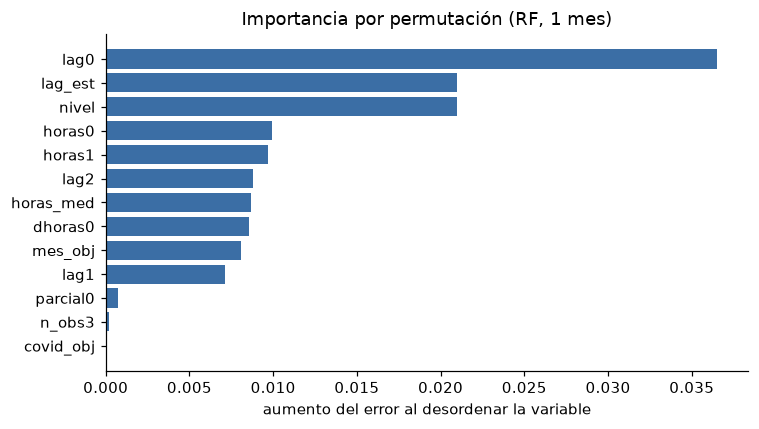

In [10]:
T_ult = PRUEBA[-1]
rf, _ = modelos_h1[T_ult]
tabla = construir_tabla(p, 1)
ev = tabla[(tabla.objetivo >= PRUEBA[0]) & tabla.y_obj.notna()]
imp = permutation_importance(rf, ev[VARIABLES], ev.y_obj - ev.nivel, n_repeats=20, random_state=0,
                             scoring="neg_mean_absolute_error")
imp_s = pd.Series(imp.importances_mean, index=VARIABLES).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp_s.index, imp_s.values, color="#3b6ea5")
ax.set(title="Importancia por permutación (RF, 1 mes)", xlabel="aumento del error al desordenar la variable")
fig.tight_layout(); fig.savefig(FIG / "s4_importancia.png"); plt.show()

**Lectura:**
- **`lag0`** (cuánto se alejó el último mes del nivel reciente) es lo más importante. El modelo aprendió a decidir **cuánto creerle al último mes**: si fue un choque, espera que se revierta (Sección 3.4).
- **`lag_est`** es la segunda más importante, aunque el ingenuo estacional fue el peor modelo. Usado solo, "igual que hace 12 meses" falla. Combinado con lo reciente, sí aporta información.
- Las variables de **horas de servicio** aparecen juntas en el bloque medio: la limitación de oferta (Sección 3.5) sí le sirve al modelo.
- **`covid_obj`** tiene importancia 0. Es lo esperado: en el periodo de prueba (2022–2023) nunca vale 1.

**Nota:** el modelo del último origen ya vio parte de estos meses al entrenar, así que la importancia es **orientativa**: sirve para ver qué usa el modelo, no para medir su error.

## 4.8 Pronósticos frente a la realidad

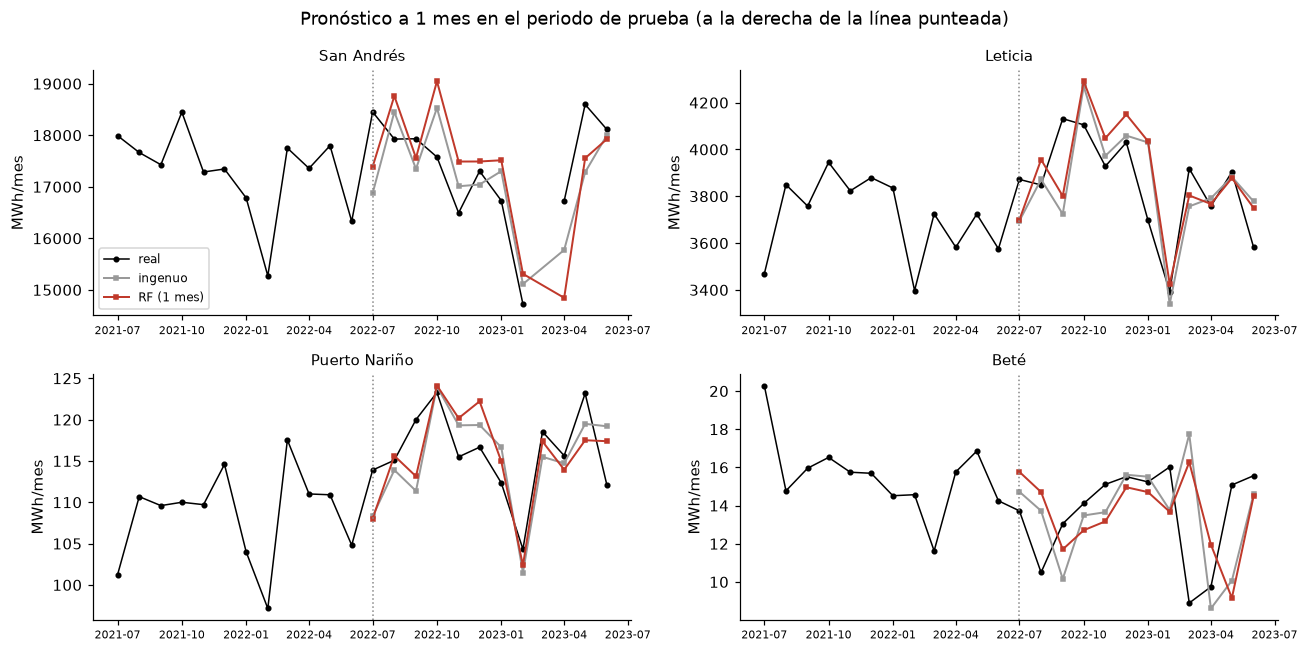

In [11]:
ejemplos = ["San Andrés", "Leticia", "Puerto Nariño", "Beté"]
fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for ax, nom in zip(axes.flat, ejemplos):
    idl = p.loc[p.nombre_corto == nom, "id_loc"].iloc[0]
    s = p[(p.id_loc == idl) & (p.fecha >= "2021-07-01")].set_index("fecha")
    ax.plot(s.index, s.e_activa / 1000, color="black", marker="o", ms=3, lw=1, label="real")
    r = res_h1[res_h1.id_loc == idl].set_index("objetivo")
    for col, c, lab in [("pred_ingenuo", "#999999", "ingenuo"), ("pred_rf", "#c0392b", "RF (1 mes)")]:
        ax.plot(r.index, np.exp(r[col]) * r.dias_obj / 1000, color=c, marker="s", ms=3, lw=1.3, label=lab)
    ax.axvline(PRUEBA[0], color="#888", ls=":", lw=1)
    ax.set_title(nom, fontsize=10); ax.set_ylabel("MWh/mes"); ax.tick_params(axis="x", labelsize=7)
axes[0, 0].legend(fontsize=8)
fig.suptitle("Pronóstico a 1 mes en el periodo de prueba (a la derecha de la línea punteada)")
fig.tight_layout(); fig.savefig(FIG / "s4_pronosticos_ejemplo.png"); plt.show()

In [12]:
# Guardar los pronósticos para la Sección 5
cols = ["id_loc", "nombre", "tamano", "origen", "objetivo", "dias_obj", "y_obj"] + list(MODELOS)
pd.concat({"1": res_h1[cols], "3": res_h3[cols]}, names=["h"]).reset_index(level=0).to_csv(
    "../datos/processed/predicciones_s4.csv", index=False)
tabla_res.round(3).to_csv("../datos/processed/metricas_s4.csv")
print("Guardado")

Guardado


**Lectura de los ejemplos:** en San Andrés y Leticia (grandes, 24 h) los pronósticos siguen la serie con un mes de "retraso". Es lo típico cuando la mejor información es el último mes. En Beté (pequeña), los choques bruscos (agosto de 2022, marzo de 2023) **no se pueden anticipar**: son fallas de servicio. Pero después de un choque, el RF tiende a esperar una recuperación más rápido que el ingenuo.

## 4.9 Conclusiones

**1. El Random Forest global es el mejor modelo, con una ventaja modesta y honesta.**

| | Mejor referencia | Random Forest global | Mejora |
|---|---|---|---|
| 1 mes · sMAPE promedio | 12,0 % (ingenuo) | **11,0 %** | −0,8 puntos (IC95 % de −1,9 a +0,2) → **no significativa** frente al ingenuo |
| 3 meses · sMAPE promedio | 15,3 % (promedio 3 meses) | **13,6 %** | −1,5 puntos (IC95 % de −2,8 a −0,1) → **significativa**; gana en el 69 % de las localidades |

**2. A 1 mes, "igual que el mes pasado" es muy difícil de superar.** Pasa en muchos estudios de pronóstico y es el motivo por el que **siempre** hay que compararse con el ingenuo. El ML aporta más a **3 meses**, donde aprovechar la reversión de choques y las horas de servicio vale más.

**3. El error depende del tipo de localidad, no del modelo.** Localidades grandes con 24 h de servicio: ~5–7 % de error con cualquier modelo. Veredas con servicio limitado: 13–20 %. El RF mejora sobre todo en las **pequeñas y medianas**. En las grandes empata con el ingenuo.

**4. El caso típico es bueno.** La mediana del sMAPE es ~6 % a 1 mes y ~7–8 % a 3 meses. El promedio es más alto por unas pocas localidades con choques de servicio.

**5. El modelo global le gana al local (ETS).** Con series cortas (Sección 1), aprender de todas las localidades a la vez funciona mejor que ajustar un modelo por localidad, como sugiere Montero-Manso & Hyndman (2021). El ETS no le ganó ni al ingenuo.

**6. Más complejo no es mejor.** El Gradient Boosting, más sofisticado, quedó por debajo del Random Forest. Con ~2.000 filas de entrenamiento, el promedio de muchos árboles (RF) es más estable.

**Limitaciones (decirlas en la presentación):**
- Los meses **sin servicio** no se pronostican: un apagón depende de fallas o de combustible, que no están en los datos.
- 12 meses de prueba es poco. Los intervalos de confianza son anchos, y por eso la mejora a 1 mes no es concluyente.
- Los hiperparámetros no se optimizaron. Hacerlo bien requiere una validación aparte, sin tocar el periodo de prueba.

**Comparación con el proyecto original:** el MAE de 0,70 horas del modelo original **no es comparable**. Medía otra variable (horas), con información del mismo mes (fuga) y con partición aleatoria. El modelo nuevo pronostica energía del **futuro**, con información **disponible** y validación **temporal**.